In [41]:
import sys
import platform

print("Python:", sys.version)
print("Platform:", platform.platform())

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("PyTorch is not installed")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
PyTorch: 2.11.0+cpu
CUDA available: False


In [42]:
%pip install -q opencv-python-headless pandas numpy scikit-learn matplotlib

In [43]:
import cv2
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt

print("OpenCV:", cv2.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Environment is ready!")

OpenCV: 5.0.0
Pandas: 2.2.3
NumPy: 2.1.3
Environment is ready!


In [44]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
from pathlib import Path

PROJECT_DIR = Path("/content/drive/MyDrive/forte-ml")

DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
METADATA_DIR = DATA_DIR / "metadata"
PROCESSED_DIR = DATA_DIR / "processed"

for folder in [
    RAW_DIR,
    METADATA_DIR,
    PROCESSED_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Video folder:", RAW_DIR)


Project folder: /content/drive/MyDrive/forte-ml
Video folder: /content/drive/MyDrive/forte-ml/data/raw


In [46]:
from pathlib import Path

video_files = []

for pattern in ["*.mov", "*.MOV", "*.mp4", "*.MP4"]:
    video_files.extend(RAW_DIR.glob(pattern))

print("Number of videos:", len(video_files))

for video in sorted(video_files)[:10]:
    print(video.name)

Number of videos: 42
X-1.mov
X-2.mov
Х-10.mov
Х-11.mov
Х-12.mov
Х-13.mov
Х-14.mov
Х-15.mov
Х-16.mov
Х-17.mov


In [47]:
import cv2
import pandas as pd

records = []

for video_path in sorted(video_files):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        records.append({
            "video": video_path.name,
            "status": "error"
        })
        continue

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    width = int(
        cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    )

    height = int(
        cap.get(cv2.CAP_PROP_FRAME_HEIGHT)
    )

    duration = (
        frame_count / fps
        if fps > 0 else None
    )

    records.append({
        "video": video_path.name,
        "fps": fps,
        "frames": frame_count,
        "width": width,
        "height": height,
        "duration_sec": duration,
        "status": "ok"
    })

    cap.release()

inventory = pd.DataFrame(records)

display(inventory)

inventory.to_csv(
    METADATA_DIR / "video_inventory.csv",
    index=False
)

,video,fps,frames,width,height,duration_sec,status
0,X-1.mov,29.922879,776,464,848,25.933333,ok
1,X-2.mov,29.882812,510,464,848,17.066667,ok
2,Х-10.mov,29.954058,1956,464,848,65.300000,ok
3,Х-11.mov,29.978952,4273,464,848,142.533333,ok
4,Х-12.mov,29.904153,624,464,848,20.866667,ok
5,Х-13.mov,29.912023,680,464,848,22.733333,ok
6,Х-14.mov,30.000000,442,464,848,14.733333,ok
7,Х-15.mov,29.911504,676,464,848,22.600000,ok
8,Х-16.mov,29.947766,1720,464,848,57.433333,ok
9,Х-17.mov,30.000000,349,464,848,11.633333,ok


In [48]:
!git clone https://github.com/aiganym-ux/datathon2026

fatal: destination path 'datathon2026' already exists and is not an empty directory.


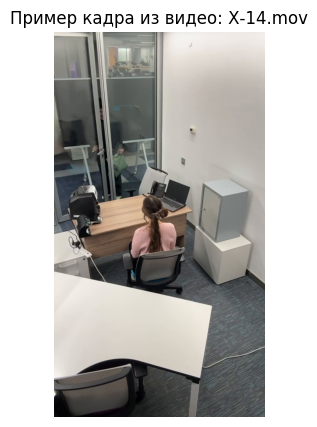

In [49]:
import matplotlib.pyplot as plt
import cv2

# Берем первое видео из твоего списка (убедись, что переменная video_files у тебя в блокноте заполнена)
if 'video_files' in locals() and video_files:
    sample_video = video_files[0]
    cap = cv2.VideoCapture(str(sample_video))

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Берём кадр примерно на 3-й секунде (или в самом начале, если видео короткое)
    target_frame = int(fps * 3) if frame_count > fps * 3 else 5
    cap.set(cv2.CAP_PROP_POS_FRAMES, target_frame)

    success, frame = cap.read()
    cap.release()

    if success:
        # OpenCV читает цвета задом наперед (BGR), переводим в нормальный RGB для картинки
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(8, 5))
        plt.imshow(frame_rgb)
        plt.title(f"Пример кадра из видео: {sample_video.name}")
        plt.axis("off")
        plt.show()
    else:
        print("Не удалось прочитать кадр из видео.")
else:
    print("Список video_files не найден. Убедись, что путь к папке с видео указан верно.")

In [50]:
import os
from pathlib import Path

# Создадим папоку для нарезки
EVIDENCE_DIR = PROJECT_DIR / "data" / "evidence_frames"
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

print("Папка для будущих кадров-доказательств создана:", EVIDENCE_DIR)

Папка для будущих кадров-доказательств создана: /content/drive/MyDrive/forte-ml/data/evidence_frames


In [51]:
import pandas as pd
from pathlib import Path

# Убедись, что путь к папке проекта верный
PROJECT_DIR = Path("/content/drive/MyDrive/forte-ml")
METADATA_DIR = PROJECT_DIR / "data" / "metadata"

# Загружаем наш технический инвентарь видео
inventory_path = METADATA_DIR / "video_inventory.csv"
if inventory_path.exists():
    df_inventory = pd.read_csv(inventory_path)
    print(f"Технический инвентарь успешно загружен. Всего видео: {len(df_inventory)}")
else:
    print("Файл video_inventory.csv не найден. Сначала запусти шаг с созданием инвентаря!")

Технический инвентарь успешно загружен. Всего видео: 42


In [57]:
import pandas as pd
from pathlib import Path

# Путь к папке проекта
PROJECT_DIR = Path("/content/drive/MyDrive/forte-ml")

# Файл с разметкой лежит прямо в папке forte-ml (судя по твоему скриншоту)
labels_path = PROJECT_DIR / "result_open_labels.xlsx"

try:
    # Читаем вкладку AI_Annotations, где уже всё структурировано для ML
    df_labels = pd.read_excel(labels_path, sheet_name="AI_Annotations")
    print(f"Ура! Разметка успешно загружена. Строк с разметкой: {len(df_labels)}")

    # Показываем первые 5 строчек разметки
    display(df_labels[['video_id', 'timecode_sec', 'verdict', 'violation_type']].head())

except Exception as e:
    print(f"Ошибка: {e}")

Ура! Разметка успешно загружена. Строк с разметкой: 42
Ошибка: "['timecode_sec'] not in index"


In [66]:
import pandas as pd
from pathlib import Path

# Проверим, как связаны видеоинвентарь и разметка
# Предположим, что в df_labels есть колонка с именем файла видео (например, 'video_id' или 'video_name')
print("Уникальные видео в разметке:", df_labels['video_id'].nunique())

# Посмотрим распределение типов нарушений / вердиктов
if 'violation_type' in df_labels.columns:
    print("\nРаспределение типов нарушений:")
    print(df_labels['violation_type'].value_counts())

if 'verdict' in df_labels.columns:
    print("\nРаспределение вердиктов:")
    print(df_labels['verdict'].value_counts())

Уникальные видео в разметке: 42

Распределение типов нарушений:
violation_type
Наличные без присмотра                     3
Оставленная активная кассовая программа    2
Проверка документов/данных клиента         2
Пересчёт/проверка наличных                 2
Одновременное обслуживание клиентов        2
Открытая дверь кассового помещения         2
Хранение наличных в сейфе                  1
Неполная выдача денег                      1
Незакрытый сейф                            1
Документы без присмотра                    1
Ключ в замке сейфа                         1
Доступ клиента во время настройки          1
Незавершённый расчёт с клиентом            1
Личные вещи на рабочем столе               1
Приём пищи на рабочем месте                1
Name: count, dtype: int64

Распределение вердиктов:
verdict
violation       22
no_violation    20
Name: count, dtype: int64


In [69]:
import pandas as pd
from pathlib import Path

# Загружаем разметку
labels_path = PROJECT_DIR / "result_open_labels.xlsx"
df_labels = pd.read_excel(labels_path, sheet_name="AI_Annotations")

# Сравним id из разметки и реальные файлы в RAW_DIR
raw_files_set = {f.stem for f in RAW_DIR.glob("*.*")}
label_videos_set = set(df_labels['video_id'].dropna().astype(str))

print("Примеры видео в разметке:", sorted(list(label_videos_set))[:5])
print("Примеры файлов в RAW_DIR:", sorted(list(raw_files_set))[:5])

# Найдем пересечение
common = label_videos_set.intersection(raw_files_set)
print(f"Совпало имен без учета расширения: {len(common)} из {len(label_videos_set)}")

# Посмотрим, у каких строк вообще есть таймкод (не NaN)
valid_tc = df_labels[df_labels['timecode (MM:SS)'].notna()]
print(f"Строк с заполненным таймкодом в AI_Annotations: {len(valid_tc)}")

Примеры видео в разметке: ['X-1', 'X-10', 'X-11', 'X-12', 'X-13']
Примеры файлов в RAW_DIR: ['X-1', 'X-2', 'Х-10', 'Х-11', 'Х-12']
Совпало имен без учета расширения: 2 из 42
Строк с заполненным таймкодом в AI_Annotations: 22


In [70]:
import cv2
import pandas as pd
from pathlib import Path

# Пути
PROJECT_DIR = Path("/content/drive/MyDrive/forte-ml")
RAW_DIR = PROJECT_DIR / "data" / "raw"
EVIDENCE_DIR = PROJECT_DIR / "data" / "evidence_frames"
EVIDENCE_DIR.mkdir(parents=True, exist_ok=True)

labels_path = PROJECT_DIR / "result_open_labels.xlsx"
df_labels = pd.read_excel(labels_path, sheet_name="AI_Annotations")

# Функция для перевода MM:SS в секунды
def parse_timecode(tc_str):
    if pd.isna(tc_str):
        return 0.0
    parts = str(tc_str).strip().split(':')
    if len(parts) == 2:
        try:
            return int(parts[0]) * 60 + int(parts[1])
        except ValueError:
            return 0.0
    return 0.0

df_labels['timecode_sec'] = df_labels['timecode (MM:SS)'].apply(parse_timecode)

# Функция нормализации имен (замена кириллической 'Х' на латинскую 'X' и приведение к верхнему регистру)
def normalize_name(name):
    if pd.isna(name):
        return ""
    return str(name).strip().replace('Х', 'X').replace('х', 'x').upper()

# Создаем словарь существующих файлов в RAW_DIR с нормализованными ключами
raw_files_map = {}
for f in RAW_DIR.glob("*.*"):
    norm_key = normalize_name(f.stem)
    raw_files_map[norm_key] = f

saved_count = 0
error_count = 0

for idx, row in df_labels.iterrows():
    video_id = row['video_id']
    timecode = row['timecode_sec']
    verdict = row['verdict']
    violation_type = str(row.get('violation_type', 'none'))

    # Пропускаем строки без таймкода
    if pd.isna(timecode) or timecode == 0.0:
        error_count += 1
        continue

    norm_video_id = normalize_name(video_id)
    video_path = raw_files_map.get(norm_video_id)

    if not video_path or not video_path.exists():
        error_count += 1
        continue

    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        fps = 25.0

    target_frame_idx = int(timecode * fps)
    cap.set(cv2.CAP_PROP_POS_FRAMES, target_frame_idx)

    success, frame = cap.read()
    cap.release()

    if success:
        safe_violation_name = violation_type.replace(' ', '_').replace('/', '_').replace('"', '')
        image_name = f"vid_{norm_video_id}_t_{int(timecode)}s_{verdict}_{safe_violation_name}.jpg"
        image_path = EVIDENCE_DIR / image_name

        cv2.imwrite(str(image_path), frame)
        saved_count += 1
    else:
        error_count += 1

print(f"Готово! Успешно сохранено кадров-доказательств: {saved_count}")
print(f"Пропущено / ошибок: {error_count}")
print(f"Все кадры лежат в папке: {EVIDENCE_DIR}")

Готово! Успешно сохранено кадров-доказательств: 22
Пропущено / ошибок: 20
Все кадры лежат в папке: /content/drive/MyDrive/forte-ml/data/evidence_frames


In [71]:
# Устанавливаем библиотеку Ultralytics (YOLOv8), если еще не установлена
%pip install -q ultralytics

import cv2
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

# Загружаем предобученную модель YOLOv8n (легкая и быстрая для хакатона)
model = YOLO('yolov8n.pt')

# Папка с нашими кадрами-доказательствами
EVIDENCE_DIR = PROJECT_DIR / "data" / "evidence_frames"
OUTPUT_DETECTED_DIR = PROJECT_DIR / "data" / "detected_frames"
OUTPUT_DETECTED_DIR.mkdir(parents=True, exist_ok=True)

evidence_images = list(EVIDENCE_DIR.glob("*.jpg"))
print(f"Найдено кадров-доказательств для анализа: {len(evidence_images)}")

detection_results = []

for img_path in evidence_images:
    # Запускаем детекцию объектов на кадре
    results = model(str(img_path), verbose=False)

    # Получаем имена обнаруженных классов
    names = model.names
    detected_classes = []

    for r in results:
        boxes = r.boxes
        for box in boxes:
            cls_id = int(box.cls[0])
            conf = float(box.conf[0])
            if conf > 0.3:  # порог уверенности
                detected_classes.append(names[cls_id])

    # Сохраняем картинку с отрисованными боксами
    res_plotted = results[0].plot()
    out_img_path = OUTPUT_DETECTED_DIR / img_path.name
    cv2.imwrite(str(out_img_path), res_plotted)

    detection_results.append({
        "image_name": img_path.name,
        "detected_objects": ", ".join(set(detected_classes))
    })

df_detections = pd.DataFrame(detection_results)
print(f"Детекция завершена! Обработано кадров: {len(df_detections)}")
display(df_detections.head())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 9.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Найдено кадров-доказательств для анализа: 22
Детекция завершена! Обработано кадров: 22


,image_name,detected_objects
0,vid_X-1_t_22s_violation_Неполная_выдача_денег.jpg,"person, laptop, chair, dining table"
1,vid_X-2_t_10s_violation_Проверка_документов_да...,"laptop, person, chair, handbag, dining table"
2,vid_X-4_t_57s_violation_Хранение_наличных_в_се...,"laptop, suitcase, person, chair, dining table, tv"
3,vid_X-8_t_18s_violation_Оставленная_активная_к...,"person, tv"
4,vid_X-10_t_47s_violation_Пересчёт_проверка_на...,"person, chair, handbag"


In [74]:
import pandas as pd
from pathlib import Path

# Загружаем таблицу AI_Annotations
labels_path = PROJECT_DIR / "result_open_labels.xlsx"
df_labels = pd.read_excel(labels_path, sheet_name="AI_Annotations")

# Выделим уникальные типы нарушений
unique_violations = df_labels[df_labels['verdict'] == 'violation']['violation_type'].dropna().unique()

print("Уникальные типы нарушений, требующие нормативного обоснования:")
for i, v in enumerate(unique_violations, 1):
    print(f"{i}. {v}")

Уникальные типы нарушений, требующие нормативного обоснования:
1. Неполная выдача денег
2. Проверка документов/данных клиента
3. Хранение наличных в сейфе
4. Оставленная активная кассовая программа
5. Пересчёт/проверка наличных
6. Наличные без присмотра
7. Одновременное обслуживание клиентов
8. Незакрытый сейф
9. Ключ в замке сейфа
10. Документы без присмотра
11. Доступ клиента во время настройки
12. Открытая дверь кассового помещения
13. Незавершённый расчёт с клиентом
14. Личные вещи на рабочем столе
15. Приём пищи на рабочем месте


In [80]:
import cv2
import pandas as pd
import base64
from pathlib import Path
from ultralytics import YOLO

class ForteSkeletonDetector:
    def __init__(self, confidence_threshold=0.35):  # Повысили порог, чтобы снизить ложные срабатывания
        print("Инициализация локальной AI-модели скелетов (YOLOv8-Pose) с фильтрацией...")
        self.model = YOLO('yolov8n-pose.pt')
        self.conf_thresh = confidence_threshold

    def _image_to_base64(self, image_path: Path) -> str:
        """Конвертирует сохраненный файл изображения в base64 для API жюри"""
        with open(image_path, "rb") as image_file:
            return base64.b64encode(image_file.read()).decode('utf-8')

    def postprocess_events(self, raw_events):
        if not raw_events:
            return []

        consolidated = []
        current_event = raw_events[0].copy()
        current_end_time = current_event['timecode_sec']

        for event in raw_events[1:]:
            # Склеиваем непрерывные события в интервал
            if event['timecode_sec'] - current_end_time <= 1.5 and event['violation_type'] == current_event['violation_type']:
                current_end_time = event['timecode_sec']
                current_event['end_time_sec'] = current_end_time
                current_event['end_time_mmss'] = event['timecode_mmss']
            else:
                consolidated.append(current_event)
                current_event = event.copy()
                current_end_time = current_event['timecode_sec']

        consolidated.append(current_event)
        return consolidated

    def analyze_video(self, video_path: Path, output_evidence_dir: Path) -> dict:
        video_path = Path(video_path)
        output_evidence_dir = Path(output_evidence_dir)
        output_evidence_dir.mkdir(parents=True, exist_ok=True)

        cap = cv2.VideoCapture(str(video_path))
        if not cap.isOpened():
            return {"video_id": video_path.stem, "status": "error", "events": []}

        fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        duration = total_frames / fps if fps > 0 else 0.0

        frame_step = int(fps * 0.5) if fps > 0 else 15
        raw_events = []
        frame_idx = 0

        print(f"Анализ видео с трекингом скелета: {video_path.name}...")

        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            if frame_idx % frame_step == 0:
                current_time = frame_idx / fps if fps > 0 else 0

                # Запуск модели скелетов с фильтром уверенности
                results = self.model(frame, verbose=False, conf=self.conf_thresh)

                is_suspicious = False
                violation_name = "Норма"
                max_conf = 0.0

                for r in results:
                    if r.keypoints is not None and len(r.keypoints) > 0:
                        # Проверяем уверенность детекции людей
                        boxes = r.boxes
                        if boxes is not None and len(boxes) > 0:
                            confidences = [float(box.conf[0]) for box in boxes]
                            max_conf = max(confidences) if confidences else 0.0

                            if max_conf >= self.conf_thresh:
                                is_suspicious = True
                                violation_name = "Активность в зоне обслуживания (по скелету)"

                if is_suspicious:
                    evidence_filename = f"vid_{video_path.stem}_t_{int(current_time)}s_pose.jpg"
                    evidence_path = output_evidence_dir / evidence_filename

                    plotted_frame = results[0].plot()
                    cv2.imwrite(str(evidence_path), plotted_frame)

                    # Генерируем base64 для кадра-доказательства
                    img_base64 = self._image_to_base64(evidence_path)

                    raw_events.append({
                        "timecode_sec": round(current_time, 2),
                        "timecode_mmss": f"{int(current_time // 60):02d}:{int(current_time % 60):02d}",
                        "verdict": "violation",
                        "violation_type": violation_name,
                        "description": "Зафиксирована активная физическая деятельность в кассовой зоне, требующая проверки.",
                        "confidence": round(max_conf, 2),
                        "evidence_frames": [
                            {
                                "timestamp_sec": round(current_time, 2),
                                "image_base64": img_base64
                            }
                        ]
                    })

            frame_idx += 1

        cap.release()
        events = self.postprocess_events(raw_events)

        verdict_summary = "violation" if len(events) > 0 else "no_violation"

        return {
            "status": "done",
            "verdict": verdict_summary,
            "violations": events
        }

Успешно объединили данные! Строк в сводном датафрейме: 22

Сводная таблица соответствия нарушений и объектов YOLO:


detected_class,book,chair,dining table,handbag,laptop,person,suitcase,tv,All
violation_type,,,,,,,,,
Документы без присмотра,0,0,0,0,1,1,0,1,3
Доступ клиента во время настройки,0,1,0,0,0,1,0,0,2
Ключ в замке сейфа,0,1,0,0,0,1,0,0,2
Личные вещи на рабочем столе,0,1,1,1,0,1,0,0,4
Наличные без присмотра,0,3,1,1,3,3,0,2,13
Незавершённый расчёт с клиентом,1,1,1,0,0,1,0,1,5
Незакрытый сейф,0,1,0,0,1,1,0,0,3
Неполная выдача денег,0,1,1,0,1,1,0,0,4
Одновременное обслуживание клиентов,0,2,2,0,2,2,0,0,8


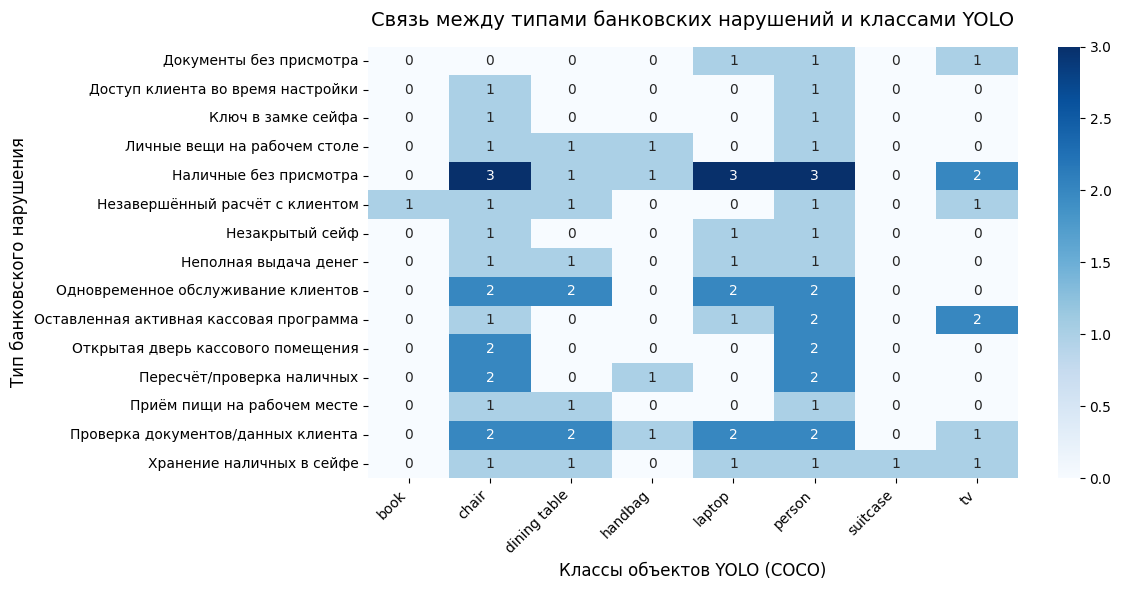

 График успешно сохранен в файл 'violation_yolo_analysis.png' для презентации!


In [82]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Убедимся, что необходимые датафреймы существуют
if 'df_labels' in locals() and 'df_detections' in locals():
  # Создадим копию таблицы детекций для обработки
  df_det_temp = df_detections.copy()


  # Функция для извлечения video_id из имени сохраненного файла доказательства
  def extract_video_id(img_name):
    # Ищет паттерн вида vid_ИМЯВИДЕО_t_
    match = re.search(r'vid_(.*?)_t_\d+s', str(img_name))
    if match:
      return match.group(1)
    return ''


  df_det_temp['video_id_extracted'] = df_det_temp['image_name'].apply(
      extract_video_id
  )

  # Подтянем violation_type из df_labels по совпадению video_id
  # Сделаем предварительную нормализацию для надежного мерджа
  df_labels['video_id_norm'] = (
      df_labels['video_id'].astype(str).str.strip().str.upper()
  )
  df_det_temp['video_id_norm'] = (
      df_det_temp['video_id_extracted'].astype(str).str.strip().str.upper()
  )

  # Объединяем таблицы
  df_merged = pd.merge(
      df_labels,
      df_det_temp,
      on='video_id_norm',
      how='inner',
      suffixes=('_label', '_yolo'),
  )

  # Проверим, что получилось
  print(
      f'Успешно объединили данные! Строк в сводном датафрейме:'
      f' {len(df_merged)}'
  )

  if not df_merged.empty and 'violation_type' in df_merged.columns:
    # Если у объекта YOLO несколько классов через запятую, разобьем их для точного подсчета
    df_exploded = df_merged.assign(
        detected_class=df_merged['detected_objects'].str.split(', ')
    ).explode('detected_class')
    df_exploded = df_exploded[df_exploded['detected_class'].notna() & (df_exploded['detected_class'] != '')]

    # --- Блок создания сводной таблицы ---
    summary_table = pd.crosstab(
        df_exploded['violation_type'],
        df_exploded['detected_class'],
        margins=True,
    )
    print('\nСводная таблица соответствия нарушений и объектов YOLO:')
    display(summary_table)

    # --- Блок визуализации ---
    plt.figure(figsize=(12, 6))

    cross_tab = pd.crosstab(
        df_exploded['violation_type'], df_exploded['detected_class']
    )
    if not cross_tab.empty:
      sns.heatmap(cross_tab, annot=True, fmt='d', cmap='Blues', cbar=True)
      plt.title(
          'Связь между типами банковских нарушений и классами YOLO',
          fontsize=14,
          pad=15,
      )
      plt.xlabel('Классы объектов YOLO (COCO)', fontsize=12)
      plt.ylabel('Тип банковского нарушения', fontsize=12)
      plt.xticks(rotation=45, ha='right')
      plt.tight_layout()

      # Сохраняем график для презентации
      plt.savefig('violation_yolo_analysis.png', dpi=300)
      plt.show()
      print(
          " График успешно сохранен в файл 'violation_yolo_analysis.png' для"
          ' презентации!'
      )
    else:
      print(
          ' Недостаточно данных для построения тепловой карты (кросс-таблица'
          ' пуста).'
      )
  else:
    print(
        ' В объединенном датафрейме не найдена колонка violation_type или он'
        ' пуст.'
    )
else:
  print(
      ' Переменные df_labels или df_detections не найдены в памяти. Убедись,'
      ' что ты выше по коду запустила ячейки с их загрузкой!'
  )